In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El cuadro de prelaciones y las duraciones (semanas) de un proyecto se adjuntan. Cada actividad tiene un responsable con su propio equipo.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 1       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 1       ),
    ('D'     , 'A,B,C'    , 2       ),
    ('E'     , 'B'        , 4       ),
    ('F'     , 'C,E'      , 1       ),
    ('G'     , 'D,F'      , 2       ),
    ('H'     , 'G'        , 1       ),
    ('I'     , 'H'        , 4       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,1
B,---,3
C,---,1
D,"A,B,C",2
E,B,4
F,"C,E",1
G,"D,F",2
H,G,1
I,H,4


La actividad crítica H va retrasada y el jefe de proyecto pide a los responsables de las actividades que se solapan con ella que cedan a alguien de su equipo durante 1 semana, lo que retrasaría la actividad cedente otras tantas. Al responsable de A le pregunta si puede.

> **De: Responsable de A (al jefe de proyecto)**
> Imposible: A no tiene ningún margen, si cedo a alguien retraso el proyecto.

> **De: Responsable de A (a un compañero, en privado)**
> A tiene margen de sobra, pero si lo digo me quitan gente cada vez que alguien va mal. El margen es mío: me lo gané planificando bien.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C4 — Retención de información.** Callar un hecho conocido que la otra parte necesitaría para decidir (un riesgo, una holgura, una discrepancia). *(cf. Código Ético del PMI, 5.3.1 y 5.2.3.)*
- **C1 — Afirmación falsa.** Comunicar como cierto un dato que quien lo comunica sabe que no lo es (un porcentaje de avance, una causa, una oferta que no existe). *(cf. Código Ético del PMI, estándar obligatorio 5.3.1; ICB4, Personas 2 «integridad personal y fiabilidad».)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule el calendario y las tres holguras (total, libre e independiente) de A, mostrando cómo se obtienen.  "
pregunta_2 = "2. (A) ¿Qué ocurre si A se retrasa 1 semana? ¿Y si consume toda su holgura total? Identifique en cada caso qué actividades se ven afectadas y si cambia la duración del proyecto.  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿qué incumple el responsable de A? ¿Es distinto decir «no tengo margen» de no mencionar el margen? ¿A quién pertenece la holgura según el criterio de la lección?  "
pregunta_4 = "4. (C) Como jefe de proyecto, ¿cómo organizaría la información sobre holguras para que esto no dependa de la buena voluntad de cada responsable? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule el calendario y las tres holguras (total, libre e independiente) de A, mostrando cómo se obtienen.  

2. (A) ¿Qué ocurre si A se retrasa 1 semana? ¿Y si consume toda su holgura total? Identifique en cada caso qué actividades se ven afectadas y si cambia la duración del proyecto.  

3. (B) Según los criterios de referencia, ¿qué incumple el responsable de A? ¿Es distinto decir «no tengo margen» de no mencionar el margen? ¿A quién pertenece la holgura según el criterio de la lección?  

4. (C) Como jefe de proyecto, ¿cómo organizaría la información sobre holguras para que esto no dependa de la buena voluntad de cada responsable? Aplique la rúbrica.  

# Resolución

In [6]:
X, Y, semanas_cedidas = 'A', 'H', 1
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = \max\{0+1,\ 0+3,\ 0+1\} = 3$ &nbsp; (A, B, C)
- $T_{E} = 0+3 = 3$ &nbsp; (B)
- $T_{F} = \max\{0+1,\ 3+4\} = 7$ &nbsp; (C, E)
- $T_{G} = \max\{3+2,\ 7+1\} = 8$ &nbsp; (D, F)
- $T_{H} = 8+2 = 10$ &nbsp; (G)
- $T_{I} = 10+1 = 11$ &nbsp; (H)
- $T_{\mathrm{Fin}} = 11+4 = 15$ &nbsp; (I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 15$
- $T_{I}^{*} = 15-4 = 11$ &nbsp; (Fin)
- $T_{H}^{*} = 11-1 = 10$ &nbsp; (I)
- $T_{G}^{*} = 10-2 = 8$ &nbsp; (H)
- $T_{F}^{*} = 8-1 = 7$ &nbsp; (G)
- $T_{E}^{*} = 7-4 = 3$ &nbsp; (F)
- $T_{D}^{*} = 8-2 = 6$ &nbsp; (G)
- $T_{C}^{*} = \min\{6-1,\ 7-1\} = 5$ &nbsp; (D, F)
- $T_{B}^{*} = \min\{6-3,\ 3-3\} = 0$ &nbsp; (D, E)
- $T_{A}^{*} = 6-1 = 5$ &nbsp; (D)
- $T_{\mathrm{Inicio}}^{*} = \min\{5-0,\ 0-0,\ 5-0\} = 0$ &nbsp; (A, B, C)

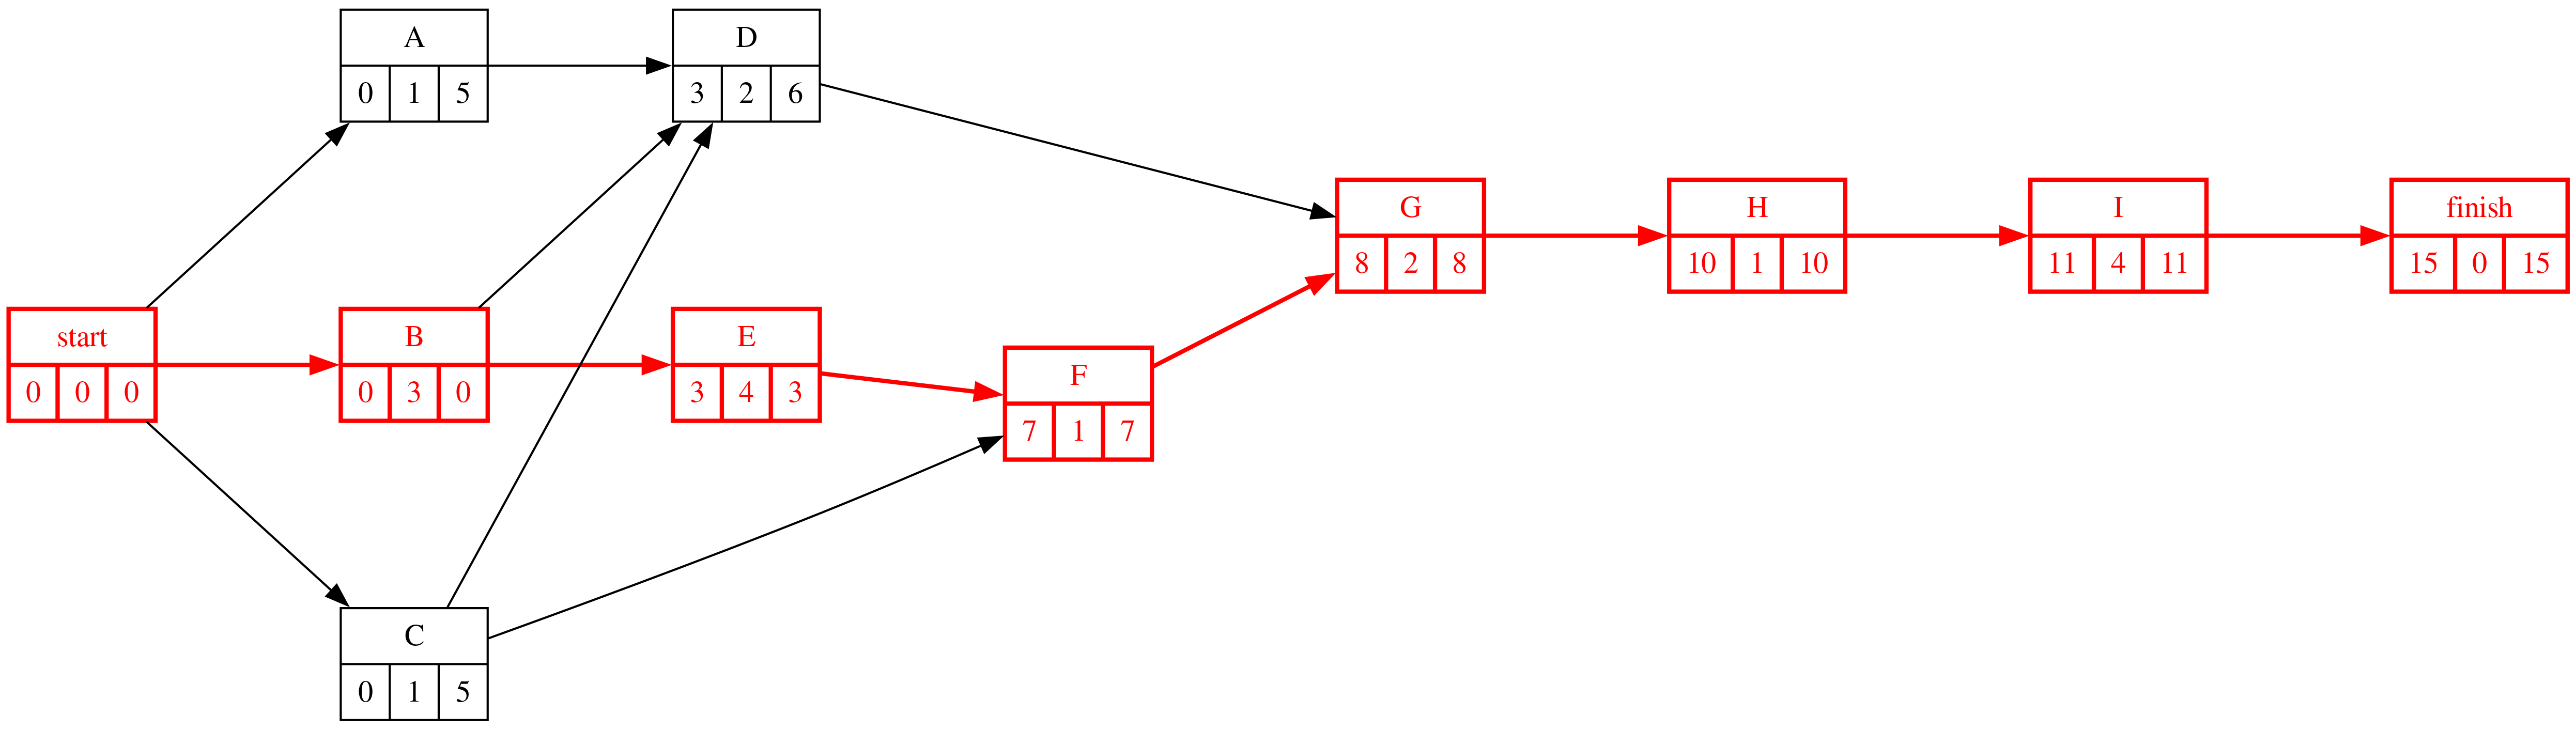

In [8]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule el calendario y las tres holguras (total, libre e independiente) de A, mostrando cómo se obtienen.  

In [10]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,5,1,6,2,2,5,1
B,0,0,3,3,0,0,0,3
C,0,5,1,6,0,0,5,1
D,3,6,5,8,3,0,3,2
E,3,3,7,7,0,0,0,4
F,7,7,8,8,0,0,0,1
G,8,8,10,10,0,0,0,2
H,10,10,11,11,0,0,0,1
I,11,11,15,15,0,0,0,4


In [11]:
#| tbl-cap: "Cómo se obtiene cada fecha y cada holgura"
#| label: tbl-detalleHolguras
detalle_holguras(calendario, prelaciones).loc[[X]].T

actividad,A
ES = máx EF pred.,inicial → 0
EF = ES + d,0 + 1 = 1
LF = mín LS suc.,mín(D: 6) = 6
LS = LF − d,6 − 1 = 5
H_total = LS − ES,5 − 0 = 5
H_libre = mín ES suc. − EF,3 − 1 = 2
"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)","máx(0, 3 − 0 − 1) = 2"


In [12]:
Ht, Hl, Hi = (int(calendario.loc[X, c]) for c in ('H_total', 'H_libre', 'H_independiente'))
Markdown(f'''{X}: holgura total **{Ht}**, libre **{Hl}**, independiente **{Hi}**. «No tiene ningún margen» es falso: puede retrasarse {Hl} semana(s) sin afectar a nadie y {Ht} sin retrasar el proyecto.''')

A: holgura total **5**, libre **2**, independiente **2**. «No tiene ningún margen» es falso: puede retrasarse 2 semana(s) sin afectar a nadie y 5 sin retrasar el proyecto.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) ¿Qué ocurre si A se retrasa 1 semana? ¿Y si consume toda su holgura total? Identifique en cada caso qué actividades se ven afectadas y si cambia la duración del proyecto.  

In [14]:
#| tbl-cap: "Holguras de las demás actividades si X se retrasa lo que se le pide y si consume toda su holgura total"
#| label: tbl-escenarios
def holguras_si_X_dura(extra):
    d = datos_proyecto['duration'].copy(); d[X] = d[X] + extra
    return proyecto.calendar(d)['H_total'], int(proyecto.duration(d))
H_ceder, T_ceder = holguras_si_X_dura(semanas_cedidas)
H_toda, T_toda = holguras_si_X_dura(Ht)
escenarios = pd.DataFrame({'plan': calendario['H_total'], f'X +{semanas_cedidas}': H_ceder, f'X +{Ht}': H_toda})
display(escenarios.T)
afectadas_ceder = [a for a in escenarios.index if a != X and H_ceder[a] < calendario.loc[a, 'H_total']]
afectadas_toda = [a for a in escenarios.index if a != X and H_toda[a] < calendario.loc[a, 'H_total']]
Markdown(f'''Retrasar {X} {semanas_cedidas} semana(s): duración {T_ceder} (= {duracion}); actividades que pierden holgura: {', '.join(afectadas_ceder) or 'ninguna'} (dentro de la holgura libre nadie se entera). Consumir toda la holgura total ({Ht}): duración {T_toda}, pero {', '.join(afectadas_toda)} {"pasa" if len(afectadas_toda) == 1 else "pasan"} a ser crítica(s): el margen que «era mío» era también de ellas.''')

activity,A,B,C,D,E,F,G,H,I
plan,5,0,5,3,0,0,0,0,0
X +1,4,0,5,3,0,0,0,0,0
X +5,0,0,5,0,0,0,0,0,0


Retrasar A 1 semana(s): duración 15 (= 15); actividades que pierden holgura: ninguna (dentro de la holgura libre nadie se entera). Consumir toda la holgura total (5): duración 15, pero D pasa a ser crítica(s): el margen que «era mío» era también de ellas.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿qué incumple el responsable de A? ¿Es distinto decir «no tengo margen» de no mencionar el margen? ¿A quién pertenece la holgura según el criterio de la lección?  

**C1 y C4.** «A no tiene ningún margen» es una **afirmación falsa** (C1): el responsable sabe que tiene 5 semanas de holgura total. Si sólo hubiera callado, sería C4, retención de información: el jefe de proyecto necesita las holguras para decidir y las holguras no son un dato privado del responsable, sino del plan. Sobre a quién pertenece la holgura el criterio de la lección es el de la holgura libre: hasta 2 semanas A puede usarla sin afectar a nadie; entre 2 y 5 la usa a costa de las actividades siguientes (D se vuelven críticas); y la decisión de a quién se asigna la holgura compartida es del jefe de proyecto, no de quien la «descubre» primero. Lo que no es objetivo —si es justo que quien planifica bien pierda su margen— se trata en C.

In [16]:
preguntas_test = [
    ('Decir «A no tiene margen» sabiendo que tiene 5 semanas de holgura total es…', ['C1, afirmación falsa', 'C4, retención de información', 'C8, reserva declarada', 'una estimación prudente'],
     'Se afirma algo que se sabe falso; callar habría sido C4.'),
    ('La holgura que una actividad puede consumir sin afectar a ninguna otra es la…', ['libre', 'total', 'independiente', 'de la ruta'],
     'Holgura libre: mín ES de las sucesoras − EF.'),
    ('Si una actividad consume toda su holgura total…', ['sus sucesoras en la misma ruta se vuelven críticas', 'el proyecto se retrasa', 'no pasa nada', 'la ruta crítica desaparece'],
     'La duración del proyecto no cambia, pero la ruta queda sin margen.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — holgura oculta')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — holgura oculta

::Ética 19 — holgura oculta P1::Decir «A no tiene margen» sabiendo que tiene 5 semanas de holgura total es… {=C1, afirmación falsa ~C4, retención de información ~C8, reserva declarada ~una estimación prudente ####Se afirma algo que se sabe falso; callar habría sido C4.}

::Ética 19 — holgura oculta P2::La holgura que una actividad puede consumir sin afectar a ninguna otra es la… {~de la ruta =libre ~independiente ~total ####Holgura libre: mín ES de las sucesoras − EF.}

::Ética 19 — holgura oculta P3::Si una actividad consume toda su holgura total… {~la ruta crítica desaparece =sus sucesoras en la misma ruta se vuelven críticas ~el proyecto se retrasa ~no pasa nada ####La duración del proyecto no cambia, pero la ruta queda sin margen.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) Como jefe de proyecto, ¿cómo organizaría la información sobre holguras para que esto no dependa de la buena voluntad de cada responsable? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Lo que depende de la buena voluntad falla; lo que está en el procedimiento no: el calendario con las tres holguras lo publica el jefe de proyecto cada semana a partir de los datos de todos, de modo que el margen de cada actividad es visible y la pregunta no es «¿tienes margen?» sino «el plan dice que tienes 2 semanas libres: te pido 1». Para el incentivo perverso («si lo digo me quitan gente»): reconocer explícitamente a quien cede, y ceder sólo dentro de la holgura libre salvo decisión del jefe de proyecto. Prueba de reversibilidad para el responsable: ¿aceptaría que el responsable de H le escondiera su margen cuando fuera él quien lo necesitara?